In [ ]:
import subprocess, sys

def pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

for pkg in ["lightgbm", "shap"]:
    try:
        __import__(pkg)
    except ImportError:
        pip_install(pkg)

print("Setup check complete.")


Setup check complete.


In [2]:
import os
import re
import math
import json
import time
import random
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

SEED = 42

def set_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

set_all_seeds(SEED)

import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: no GPU detected. Turn on the T4 accelerator in the "
          "session settings panel, or Stage 3 fine-tuning will be very slow.")


Device: cuda


In [3]:
INPUT_ROOT = "/kaggle/input"

found_files = []
for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
    for fn in filenames:
        full = os.path.join(dirpath, fn)
        found_files.append(full)

print(f"Found {len(found_files)} file(s) under {INPUT_ROOT}:\n")
for f in found_files:
    size_kb = os.path.getsize(f) / 1024
    print(f"  {f}   ({size_kb:,.1f} KB)")

print("\n--- Peeking at tabular files ---\n")
candidate_tables = [f for f in found_files if f.lower().endswith((".csv", ".tsv"))]
for f in candidate_tables:
    sep = "\t" if f.lower().endswith(".tsv") else ","
    try:
        preview = pd.read_csv(f, sep=sep, nrows=5, encoding_errors="replace")
    except Exception as e:
        print(f"[{f}] could not be read with pandas: {e}\n")
        continue
    print(f"[{f}]")
    print("  columns:", list(preview.columns))
    print("  sample row:", preview.iloc[0].to_dict() if len(preview) else "(empty)")
    print()


Found 1 file(s) under /kaggle/input:

  /kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv   (491.9 KB)

--- Peeking at tabular files ---

[/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv]
  columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
  sample row: {'v1': 'ham', 'v2': 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...', 'Unnamed: 2': nan, 'Unnamed: 3': nan, 'Unnamed: 4': nan}



In [ ]:
DATA_PATH = "/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv"
TEXT_COL = "v2"
LABEL_COL = "v1"

raw_df = pd.read_csv(DATA_PATH, encoding_errors="replace")
print("Loaded shape:", raw_df.shape)
print("Columns:", list(raw_df.columns))
assert TEXT_COL in raw_df.columns, f"{TEXT_COL} is not a real column. Fix TEXT_COL above."
assert LABEL_COL in raw_df.columns, f"{LABEL_COL} is not a real column. Fix LABEL_COL above."
raw_df[[TEXT_COL, LABEL_COL]].head(10)


Loaded shape: (5572, 5)
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v2,v1
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham
5,FreeMsg Hey there darling it's been 3 week's n...,spam
6,Even my brother is not like to speak with me. ...,ham
7,As per your request 'Melle Melle (Oru Minnamin...,ham
8,WINNER!! As a valued network customer you have...,spam
9,Had your mobile 11 months or more? U R entitle...,spam


In [5]:
print("Raw label value counts:")
print(raw_df[LABEL_COL].value_counts(dropna=False))


Raw label value counts:
v1
ham     4825
spam     747
Name: count, dtype: int64


In [ ]:
PHISHING_LABELS = {
    "spam", "phishing", "phish", "1", 1, 1.0, True, "yes", "malicious",
}

def to_binary_label(v):
    if pd.isna(v):
        return np.nan
    key = str(v).strip().lower()
    if key in {str(x).lower() for x in PHISHING_LABELS}:
        return 1
    return 0

df = raw_df[[TEXT_COL, LABEL_COL]].copy()
df.columns = ["text", "label"]
df["label"] = df["label"].apply(to_binary_label)

before = len(df)
df = df.dropna(subset=["text", "label"])
df["text"] = df["text"].astype(str)
df = df[df["text"].str.strip().str.len() > 0]
df = df.drop_duplicates(subset=["text"])
df["label"] = df["label"].astype(int)
after = len(df)

print(f"Rows before cleaning: {before}")
print(f"Rows after cleaning:  {after}")
print("\nFinal label balance:")
print(df["label"].value_counts())
print("\nCheck this balance by hand: if it does not roughly match what you "
      "expect (phishing should usually be the minority class), PHISHING_LABELS "
      "above is probably wrong and labels got inverted or lost.")

df = df.reset_index(drop=True)
df.head()


Rows before cleaning: 5572
Rows after cleaning:  5169

Final label balance:
label
0    4516
1     653
Name: count, dtype: int64

Check this balance by hand: if it does not roughly match what you expect (phishing should usually be the minority class), PHISHING_LABELS above is probably wrong and labels got inverted or lost.


,text,label
0,"Go until jurong point, crazy.. Available only ...",0
1,Ok lar... Joking wif u oni...,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives aro...",0


In [7]:
from sklearn.model_selection import train_test_split

train_df, rest_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    rest_df, test_size=0.50, stratify=rest_df["label"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print("\nTrain label balance:\n", train_df['label'].value_counts(normalize=True))
print("\nVal label balance:\n", val_df['label'].value_counts(normalize=True))
print("\nTest label balance:\n", test_df['label'].value_counts(normalize=True))


Train: 3618  Val: 775  Test: 776

Train label balance:
 label
0    0.873687
1    0.126313
Name: proportion, dtype: float64

Val label balance:
 label
0    0.873548
1    0.126452
Name: proportion, dtype: float64

Test label balance:
 label
0    0.873711
1    0.126289
Name: proportion, dtype: float64


In [ ]:
HOMOGLYPH_MAP = {
    "a": "\u0430",
    "e": "\u0435",
    "o": "\u043e",
    "p": "\u0440",
    "c": "\u0441",
    "x": "\u0445",
}
HOMOGLYPH_REVERSE = {v: k for k, v in HOMOGLYPH_MAP.items()}

LEET_MAP = {
    "a": "@", "e": "3", "i": "!", "o": "0",
    "s": "$", "t": "7", "l": "1", "g": "9",
}
LEET_REVERSE = {v: k for k, v in LEET_MAP.items()}

ZWSP = "\u200b"

ATTACK_TYPES = ["homoglyph", "leetspeak", "zwsp"]
INTENSITIES = [0.10, 0.25, 0.50]


def _eligible_positions(text, mapping):
    return [i for i, ch in enumerate(text) if ch.lower() in mapping]


def perturb_text(text, attack, intensity, rng):
    """attack in {'homoglyph','leetspeak','zwsp'}; intensity in [0, 1]."""
    if intensity <= 0:
        return text

    if attack in ("homoglyph", "leetspeak"):
        mapping = HOMOGLYPH_MAP if attack == "homoglyph" else LEET_MAP
        positions = _eligible_positions(text, mapping)
        if not positions:
            return text
        n_hit = round(len(positions) * intensity)
        chosen = set(rng.sample(positions, n_hit)) if n_hit > 0 else set()
        out = []
        for i, ch in enumerate(text):
            out.append(mapping[ch.lower()] if i in chosen else ch)
        return "".join(out)

    if attack == "zwsp":
        positions = [i for i, ch in enumerate(text) if ch.isalpha()]
        if not positions:
            return text
        n_hit = round(len(positions) * intensity)
        chosen = sorted(rng.sample(positions, n_hit)) if n_hit > 0 else []
        out = []
        last = 0
        for i in chosen:
            out.append(text[last:i + 1])
            out.append(ZWSP)
            last = i + 1
        out.append(text[last:])
        return "".join(out)

    raise ValueError(f"unknown attack {attack!r}")


def build_perturbed_column(texts, attack, intensity, seed=SEED):
    rng = random.Random(seed)
    return [perturb_text(t, attack, intensity, rng) for t in texts]


In [ ]:
# Quick sanity check
_example = "Dear customer, your PayPal account needs verification. Click http://paypa1-verify.com now!!!"
for attack in ATTACK_TYPES:
    for intensity in INTENSITIES:
        rng = random.Random(SEED)
        print(f"[{attack:>10} @ {intensity:.0%}] {perturb_text(_example, attack, intensity, rng)}")
    print()


[ homoglyph @ 10%] Dеar custоmer, your PayPal account needs verification. сlick http://paypa1-verify.com now!!!
[ homoglyph @ 25%] Dеar custоmеr, your Pаyрal account needs verification. сlick http://рayрa1-verify.com now!!!
[ homoglyph @ 50%] Dеаr сustоmеr, your Pаyрal accоunt needs verifiсаtion. сliсk http://рayрa1-verify.соm now!!!

[ leetspeak @ 10%] De@r customer, your P@yPal account needs ver!fication. Click http://paypa1-verify.com now!!!
[ leetspeak @ 25%] De@r cust0mer, your P@yP@l account needs verification. C1ick http://payp@1-ver!fy.com n0w!!!
[ leetspeak @ 50%] D3@r cu$70mer, your P@yP@l account n3eds ver!f!cat!on. C1ick http://payp@1-ver!fy.c0m n0w!!!

[      zwsp @ 10%] Dear​ customer, yo​u​r Pa​yPal account​ nee​ds ve​rification. Click http://paypa1-verify.com now!!!
[      zwsp @ 25%] De​a​r​ cu​stomer​, yo​u​r Pa​yPal account​ nee​d​s ve​rif​ication. Click http​://paypa1-ve​rify​.com n​ow​!!!
[      zwsp @ 50%] D​e​a​r​ cu​stom​e​r​, y​o​u​r Pa​yPal​ accou​n​t​ nee​d​s

In [ ]:
test_sets = {"clean": test_df.copy()}

for attack in ATTACK_TYPES:
    for intensity in INTENSITIES:
        key = f"{attack}_{int(intensity * 100)}"
        perturbed = test_df.copy()
        perturbed["text"] = build_perturbed_column(
            test_df["text"].tolist(), attack, intensity, seed=SEED
        )
        test_sets[key] = perturbed

print(f"Built {len(test_sets)} test sets:", list(test_sets.keys()))
print("\nExample row, clean vs. homoglyph_50:")
print("clean:        ", test_sets["clean"]["text"].iloc[0])
print("homoglyph_50: ", test_sets["homoglyph_50"]["text"].iloc[0])


Built 10 test sets: ['clean', 'homoglyph_10', 'homoglyph_25', 'homoglyph_50', 'leetspeak_10', 'leetspeak_25', 'leetspeak_50', 'zwsp_10', 'zwsp_25', 'zwsp_50']

Example row, clean vs. homoglyph_50:
clean:         In which place do you want da.
homoglyph_50:  In whiсh рlаce dо you want da.


In [11]:
KEYWORDS = [
    "verify", "account", "password", "urgent", "click", "bank",
    "suspend", "confirm", "login", "update", "security", "winner",
    "free", "prize", "congratulations", "limited", "act now",
]

URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
IP_RE = re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b")


def normalize_for_keywords(text):
    out = []
    for ch in text:
        if ch == ZWSP:
            continue
        if ch in HOMOGLYPH_REVERSE:
            out.append(HOMOGLYPH_REVERSE[ch])
        elif ch in LEET_REVERSE:
            out.append(LEET_REVERSE[ch])
        else:
            out.append(ch)
    return "".join(out).lower()


def keyword_count(text):
    norm = normalize_for_keywords(text)
    return sum(norm.count(k) for k in KEYWORDS)


def shannon_entropy(text):
    if not text:
        return 0.0
    counts = {}
    for ch in text:
        counts[ch] = counts.get(ch, 0) + 1
    n = len(text)
    return -sum((c / n) * math.log2(c / n) for c in counts.values())


FEATURE_NAMES = [
    "entropy", "non_ascii_ratio", "digit_letter_ratio", "uppercase_ratio",
    "punct_density", "has_url", "has_ip", "keyword_count",
    "length_chars", "length_tokens",
]


def extract_features(text, token_len_fn=None):
    if token_len_fn is None:
        token_len_fn = lambda t: len(t.split())

    n_chars = len(text)
    letters = [c for c in text if c.isalpha()]
    digits = [c for c in text if c.isdigit()]
    upper = [c for c in letters if c.isupper()]
    punct = [c for c in text if not c.isalnum() and not c.isspace()]
    non_ascii = [c for c in text if ord(c) > 127]
    n_letters = max(len(letters), 1)

    return {
        "entropy": shannon_entropy(text),
        "non_ascii_ratio": len(non_ascii) / max(n_chars, 1),
        "digit_letter_ratio": len(digits) / n_letters,
        "uppercase_ratio": len(upper) / n_letters,
        "punct_density": len(punct) / max(n_chars, 1),
        "has_url": float(bool(URL_RE.search(text))),
        "has_ip": float(bool(IP_RE.search(text))),
        "keyword_count": float(keyword_count(text)),
        "length_chars": float(n_chars),
        "length_tokens": float(token_len_fn(text)),
    }


def features_for_df(dframe, token_len_fn=None):
    rows = [extract_features(t, token_len_fn) for t in dframe["text"]]
    return pd.DataFrame(rows, columns=FEATURE_NAMES)


In [ ]:
from sklearn.preprocessing import StandardScaler

f_meta_train_raw = features_for_df(train_df)
f_meta_val_raw = features_for_df(val_df)

meta_scaler = StandardScaler()
meta_scaler.fit(f_meta_train_raw.values)

f_meta_train = meta_scaler.transform(f_meta_train_raw.values)
f_meta_val = meta_scaler.transform(f_meta_val_raw.values)

f_meta_test_sets = {}
for key, sub_df in test_sets.items():
    raw = features_for_df(sub_df)
    f_meta_test_sets[key] = meta_scaler.transform(raw.values)

print("f_meta_train shape:", f_meta_train.shape)
print("f_meta_val shape:  ", f_meta_val.shape)
print("f_meta_test_sets['clean'] shape:", f_meta_test_sets["clean"].shape)
print("\nFeature order:", FEATURE_NAMES)


f_meta_train shape: (3618, 10)
f_meta_val shape:   (775, 10)
f_meta_test_sets['clean'] shape: (776, 10)

Feature order: ['entropy', 'non_ascii_ratio', 'digit_letter_ratio', 'uppercase_ratio', 'punct_density', 'has_url', 'has_ip', 'keyword_count', 'length_chars', 'length_tokens']


In [13]:
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import f1_score

MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 128
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
NUM_EPOCHS = 4
EARLY_STOP_PATIENCE = 1

tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)


class TextClsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


train_dataset = TextClsDataset(train_df["text"], train_df["label"], tokenizer, MAX_LEN)
val_dataset = TextClsDataset(val_df["text"], val_df["label"], tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

distil_model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2
).to(DEVICE)

optimizer = AdamW(distil_model.parameters(), lr=LEARNING_RATE)

print(f"Train batches: {len(train_loader)}  Val batches: {len(val_loader)}")


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Train batches: 227  Val batches: 49


In [14]:
def run_eval(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            labels = batch.pop("labels").to(DEVICE)
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            logits = model(**batch).logits
            preds = torch.argmax(logits, dim=-1)
            all_preds.extend(preds.cpu().numpy().tolist())
            all_labels.extend(labels.cpu().numpy().tolist())
    return f1_score(all_labels, all_preds)


best_val_f1 = -1.0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, NUM_EPOCHS + 1):
    distil_model.train()
    running_loss = 0.0
    for batch in train_loader:
        labels = batch.pop("labels").to(DEVICE)
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        optimizer.zero_grad()
        outputs = distil_model(**batch, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    val_f1 = run_eval(distil_model, val_loader)
    print(f"Epoch {epoch}: train loss {running_loss / len(train_loader):.4f}, val F1 {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {k: v.detach().cpu().clone() for k, v in distil_model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOP_PATIENCE:
            print(f"Early stopping after epoch {epoch} (no improvement for "
                  f"{EARLY_STOP_PATIENCE} epoch(s)).")
            break

distil_model.load_state_dict(best_state)
distil_model.to(DEVICE)
print(f"\nLoaded best checkpoint, validation F1 = {best_val_f1:.4f}")


Epoch 1: train loss 0.0952, val F1 0.9524
Epoch 2: train loss 0.0278, val F1 0.9634
Epoch 3: train loss 0.0138, val F1 0.9500
Early stopping after epoch 3 (no improvement for 1 epoch(s)).

Loaded best checkpoint, validation F1 = 0.9634


In [15]:
@torch.no_grad()
def extract_cls_embeddings(model, texts, tokenizer, max_len=MAX_LEN, batch_size=32):
    model.eval()
    all_vecs = []
    for start in range(0, len(texts), batch_size):
        batch_texts = list(texts[start:start + batch_size])
        enc = tokenizer(
            batch_texts, truncation=True, padding="max_length",
            max_length=max_len, return_tensors="pt",
        ).to(DEVICE)
        outputs = model.distilbert(**enc)
        cls_vecs = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        all_vecs.append(cls_vecs.cpu().numpy())
    return np.concatenate(all_vecs, axis=0)


e_distil_train = extract_cls_embeddings(distil_model, train_df["text"].tolist(), tokenizer)
e_distil_val = extract_cls_embeddings(distil_model, val_df["text"].tolist(), tokenizer)

e_distil_test_sets = {}
for key, sub_df in test_sets.items():
    e_distil_test_sets[key] = extract_cls_embeddings(distil_model, sub_df["text"].tolist(), tokenizer)

print("e_distil_train shape:", e_distil_train.shape)
print("e_distil_val shape:  ", e_distil_val.shape)
print("e_distil_test_sets['clean'] shape:", e_distil_test_sets["clean"].shape)


e_distil_train shape: (3618, 768)
e_distil_val shape:   (775, 768)
e_distil_test_sets['clean'] shape: (776, 768)


In [ ]:
v_fused_train = np.concatenate([e_distil_train, f_meta_train], axis=1)
v_fused_val = np.concatenate([e_distil_val, f_meta_val], axis=1)
v_fused_test_sets = {
    key: np.concatenate([e_distil_test_sets[key], f_meta_test_sets[key]], axis=1)
    for key in test_sets
}

print("v_fused_train shape:", v_fused_train.shape, "(768 + k =", v_fused_train.shape[1], ")")


v_fused_train shape: (3618, 778) (768 + k = 778 )


In [17]:
import lightgbm as lgb

LGB_PARAMS = dict(
    n_estimators=300,
    num_leaves=31,
    max_depth=-1,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
    n_jobs=-1,
)


def train_lgb(X_train, y_train, X_val, y_val):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)],
    )
    return model


y_train = train_df["label"].values
y_val = val_df["label"].values

print("Training M2 (GBDT on e_distil alone)...")
m2_model = train_lgb(e_distil_train, y_train, e_distil_val, y_val)

print("Training M3 (GBDT on v_fused)...")
m3_model = train_lgb(v_fused_train, y_train, v_fused_val, y_val)

print("M2 and M3 trained.")


Training M2 (GBDT on e_distil alone)...
[LightGBM] [Info] Number of positive: 457, number of negative: 3161
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.026501 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 195840
[LightGBM] [Info] Number of data points in the train set: 3618, number of used features: 768
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.126313 -> initscore=-1.933960
[LightGBM] [Info] Start training from score -1.933960
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training M3 (GBDT

In [ ]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

@torch.no_grad()
def m1_predict(model, texts, tokenizer, max_len=MAX_LEN, batch_size=32):
    model.eval()
    all_preds, all_probs = [], []
    for start in range(0, len(texts), batch_size):
        batch_texts = list(texts[start:start + batch_size])
        enc = tokenizer(
            batch_texts, truncation=True, padding="max_length",
            max_length=max_len, return_tensors="pt",
        ).to(DEVICE)
        logits = model(**enc).logits
        probs = torch.softmax(logits, dim=-1)[:, 1]
        preds = torch.argmax(logits, dim=-1)
        all_preds.extend(preds.cpu().numpy().tolist())
        all_probs.extend(probs.cpu().numpy().tolist())
    return np.array(all_preds), np.array(all_probs)


def compute_metrics(y_true, y_pred, y_prob):
    return {
        "f1": f1_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob) if len(set(y_true)) > 1 else float("nan"),
    }


results = []

for key, sub_df in test_sets.items():
    y_true = sub_df["label"].values

    # M1: DistilBERT with softmax head, predicts directly from text.
    preds_m1, probs_m1 = m1_predict(distil_model, sub_df["text"].tolist(), tokenizer)
    metrics_m1 = compute_metrics(y_true, preds_m1, probs_m1)
    results.append({"model": "M1", "test_set": key, **metrics_m1})

    # M2: GBDT on e_distil alone.
    X_m2 = e_distil_test_sets[key]
    probs_m2 = m2_model.predict_proba(X_m2)[:, 1]
    preds_m2 = (probs_m2 >= 0.5).astype(int)
    metrics_m2 = compute_metrics(y_true, preds_m2, probs_m2)
    results.append({"model": "M2", "test_set": key, **metrics_m2})

    # M3: GBDT on v_fused.
    X_m3 = v_fused_test_sets[key]
    probs_m3 = m3_model.predict_proba(X_m3)[:, 1]
    preds_m3 = (probs_m3 >= 0.5).astype(int)
    metrics_m3 = compute_metrics(y_true, preds_m3, probs_m3)
    results.append({"model": "M3", "test_set": key, **metrics_m3})

results_df = pd.DataFrame(results)
results_df.to_csv("all_metrics.csv", index=False)
results_df


,model,test_set,f1,precision,recall,roc_auc
0,M1,clean,0.984615,0.989691,0.979592,0.996689
1,M2,clean,0.984615,0.989691,0.979592,0.980359
2,M3,clean,0.984615,0.989691,0.979592,0.981473
3,M1,homoglyph_10,0.968750,0.989362,0.948980,0.995906
4,M2,homoglyph_10,0.974093,0.989474,0.959184,0.983211
5,M3,homoglyph_10,0.979381,0.989583,0.969388,0.991105
6,M1,homoglyph_25,0.940541,1.000000,0.887755,0.996975
7,M2,homoglyph_25,0.934783,1.000000,0.877551,0.981654
8,M3,homoglyph_25,0.940541,1.000000,0.887755,0.980209
9,M1,homoglyph_50,0.898876,1.000000,0.816327,0.995951


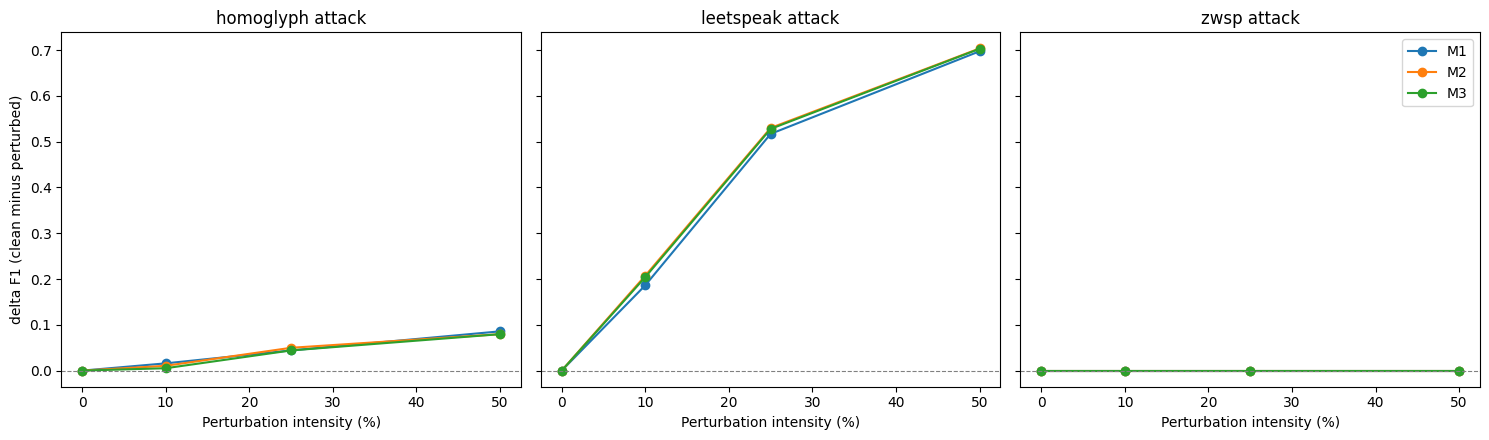

In [19]:
import matplotlib.pyplot as plt

clean_f1 = {
    model: results_df[(results_df["model"] == model) & (results_df["test_set"] == "clean")]["f1"].iloc[0]
    for model in ["M1", "M2", "M3"]
}

fig, axes = plt.subplots(1, len(ATTACK_TYPES), figsize=(15, 4.5), sharey=True)

for ax, attack in zip(axes, ATTACK_TYPES):
    for model in ["M1", "M2", "M3"]:
        xs = [0] + [int(i * 100) for i in INTENSITIES]
        ys = [0.0]
        for intensity in INTENSITIES:
            key = f"{attack}_{int(intensity * 100)}"
            f1_here = results_df[(results_df["model"] == model) & (results_df["test_set"] == key)]["f1"].iloc[0]
            ys.append(clean_f1[model] - f1_here)
        ax.plot(xs, ys, marker="o", label=model)
    ax.set_title(f"{attack} attack")
    ax.set_xlabel("Perturbation intensity (%)")
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

axes[0].set_ylabel("delta F1 (clean minus perturbed)")
axes[-1].legend()
plt.tight_layout()
plt.savefig("degradation_curves.png", dpi=150)
plt.show()


In [ ]:
import shap

v_fused_feature_names = [f"e_distil_{i}" for i in range(e_distil_train.shape[1])] + FEATURE_NAMES

explainer = shap.TreeExplainer(m3_model)

SHAP_SAMPLE_SIZE = min(200, len(v_fused_test_sets["clean"]))
rng_idx = np.random.RandomState(SEED).choice(
    len(v_fused_test_sets["clean"]), size=SHAP_SAMPLE_SIZE, replace=False
)

shap_clean = explainer.shap_values(v_fused_test_sets["clean"][rng_idx])
shap_attacked = explainer.shap_values(v_fused_test_sets["homoglyph_50"][rng_idx])

if isinstance(shap_clean, list):
    shap_clean = shap_clean[1]
    shap_attacked = shap_attacked[1]

print("Mean absolute SHAP value, clean, top 10 features:")
mean_abs_clean = np.abs(shap_clean).mean(axis=0)
order_clean = np.argsort(mean_abs_clean)[::-1][:10]
for i in order_clean:
    print(f"  {v_fused_feature_names[i]:<20} {mean_abs_clean[i]:.4f}")

print("\nMean absolute SHAP value, homoglyph @ 50%, top 10 features:")
mean_abs_attacked = np.abs(shap_attacked).mean(axis=0)
order_attacked = np.argsort(mean_abs_attacked)[::-1][:10]
for i in order_attacked:
    print(f"  {v_fused_feature_names[i]:<20} {mean_abs_attacked[i]:.4f}")

handcrafted_start = e_distil_train.shape[1]
handcrafted_share_clean = mean_abs_clean[handcrafted_start:].sum() / mean_abs_clean.sum()
handcrafted_share_attacked = mean_abs_attacked[handcrafted_start:].sum() / mean_abs_attacked.sum()
print(f"\nShare of total |SHAP| carried by the 10 handcrafted features:")
print(f"  clean:            {handcrafted_share_clean:.2%}")
print(f"  homoglyph @ 50%:  {handcrafted_share_attacked:.2%}")
print("If fusion is doing real work under attack, the second number should "
      "be noticeably larger than the first.")


Mean absolute SHAP value, clean, top 10 features:
  e_distil_453         0.5397
  e_distil_709         0.4144
  e_distil_404         0.2125
  e_distil_731         0.1697
  e_distil_693         0.1408
  e_distil_755         0.1404
  e_distil_525         0.0819
  e_distil_729         0.0700
  e_distil_197         0.0600
  e_distil_495         0.0192

Mean absolute SHAP value, homoglyph @ 50%, top 10 features:
  e_distil_453         0.5042
  e_distil_709         0.3597
  e_distil_404         0.1796
  e_distil_731         0.1533
  e_distil_755         0.1467
  e_distil_693         0.1342
  e_distil_525         0.0724
  e_distil_729         0.0710
  e_distil_197         0.0614
  e_distil_621         0.0227

Share of total |SHAP| carried by the 10 handcrafted features:
  clean:            0.03%
  homoglyph @ 50%:  0.03%
If fusion is doing real work under attack, the second number should be noticeably larger than the first.


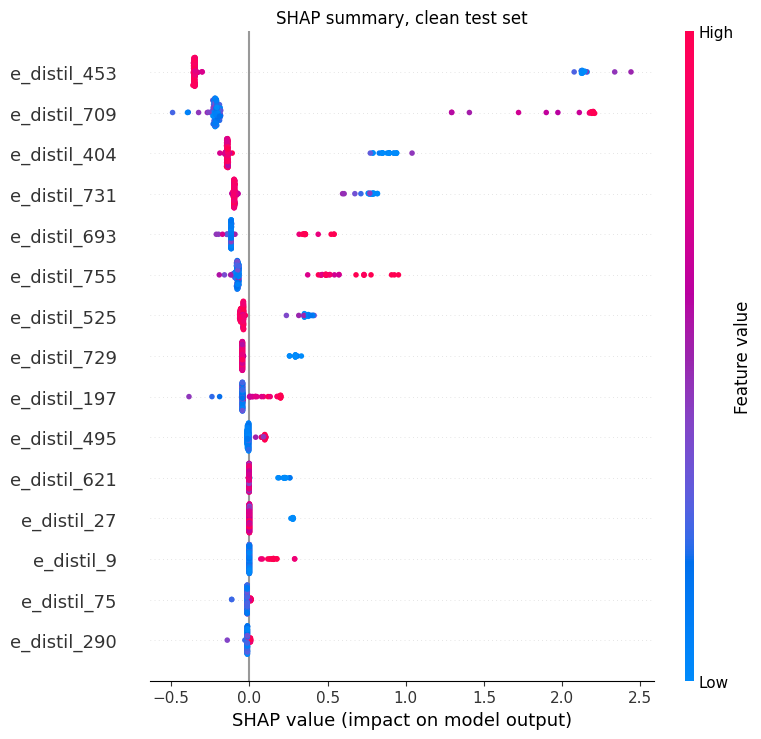

In [21]:
shap.summary_plot(shap_clean, features=v_fused_test_sets["clean"][rng_idx],
                   feature_names=v_fused_feature_names, max_display=15, show=False)
plt.title("SHAP summary, clean test set")
plt.tight_layout()
plt.savefig("shap_clean.png", dpi=150, bbox_inches="tight")
plt.show()


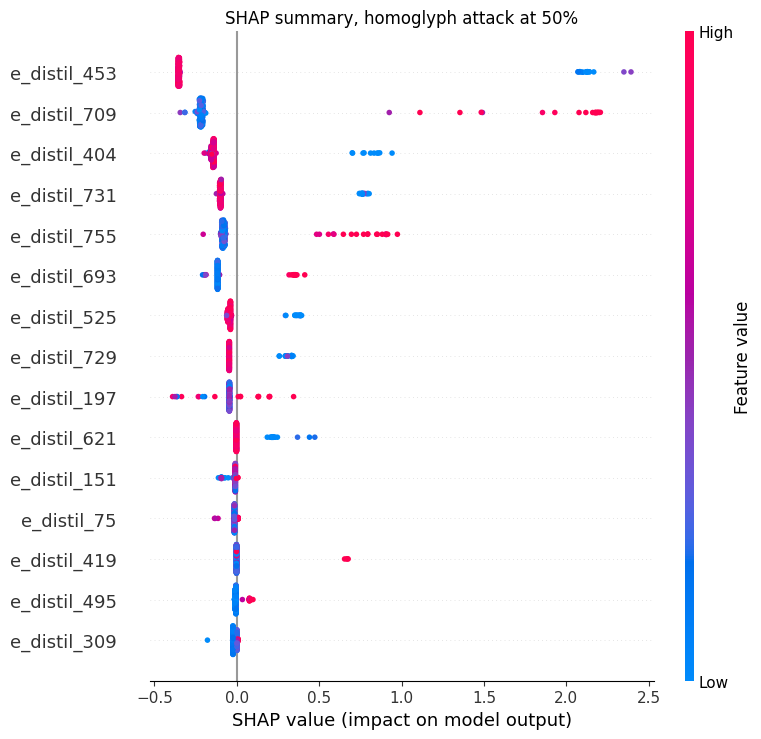

In [22]:
shap.summary_plot(shap_attacked, features=v_fused_test_sets["homoglyph_50"][rng_idx],
                   feature_names=v_fused_feature_names, max_display=15, show=False)
plt.title("SHAP summary, homoglyph attack at 50%")
plt.tight_layout()
plt.savefig("shap_attacked.png", dpi=150, bbox_inches="tight")
plt.show()


In [23]:
def measure_latency_ms(predict_fn, texts_or_vectors, n_repeats=3):
    """Runs predict_fn once per item, n_repeats times, returns mean ms/item."""
    times = []
    for _ in range(n_repeats):
        start = time.perf_counter()
        predict_fn(texts_or_vectors)
        elapsed = time.perf_counter() - start
        times.append(elapsed)
    mean_elapsed = sum(times) / len(times)
    return (mean_elapsed / len(texts_or_vectors)) * 1000.0


LATENCY_SAMPLE = test_sets["clean"]["text"].tolist()[:100]
LATENCY_SAMPLE_EMB = e_distil_test_sets["clean"][:100]
LATENCY_SAMPLE_FUSED = v_fused_test_sets["clean"][:100]

m1_latency = measure_latency_ms(
    lambda texts: m1_predict(distil_model, texts, tokenizer), LATENCY_SAMPLE
)
m2_latency = measure_latency_ms(
    lambda X: m2_model.predict(X), LATENCY_SAMPLE_EMB
)
m3_latency = measure_latency_ms(
    lambda X: m3_model.predict(X), LATENCY_SAMPLE_FUSED
)

print(f"M1 (DistilBERT, softmax head): {m1_latency:.3f} ms/message")
print(f"M2 (GBDT on embedding alone):   {m2_latency:.3f} ms/message")
print(f"M3 (GBDT on fused vector):      {m3_latency:.3f} ms/message")
print("\nNote: M2 and M3 latency above counts only the tree model's own "
      "predict call, not the cost of producing e_distil in the first place. "
      "If you report end-to-end latency for M2/M3 in the paper, add the "
      "DistilBERT forward-pass time (the loop that built e_distil_test_sets "
      "above) on top of these numbers, since both models still need that "
      "embedding to run.")


M1 (DistilBERT, softmax head): 3.877 ms/message
M2 (GBDT on embedding alone):   0.026 ms/message
M3 (GBDT on fused vector):      0.022 ms/message

Note: M2 and M3 latency above counts only the tree model's own predict call, not the cost of producing e_distil in the first place. If you report end-to-end latency for M2/M3 in the paper, add the DistilBERT forward-pass time (the loop that built e_distil_test_sets above) on top of these numbers, since both models still need that embedding to run.


In [24]:
summary_pivot = results_df.pivot(index="test_set", columns="model", values="f1")
row_order = ["clean"] + [f"{a}_{int(i*100)}" for a in ATTACK_TYPES for i in INTENSITIES]
summary_pivot = summary_pivot.reindex(row_order)
summary_pivot.to_csv("summary_f1_pivot.csv")
summary_pivot


model,M1,M2,M3
test_set,,,
clean,0.984615,0.984615,0.984615
homoglyph_10,0.968750,0.974093,0.979381
homoglyph_25,0.940541,0.934783,0.940541
homoglyph_50,0.898876,0.905028,0.905028
leetspeak_10,0.798354,0.777328,0.780488
leetspeak_25,0.467780,0.454756,0.456876
leetspeak_50,0.287390,0.281205,0.282014
zwsp_10,0.984615,0.984615,0.984615
zwsp_25,0.984615,0.984615,0.984615


In [25]:
shap_leet50 = explainer.shap_values(v_fused_test_sets["leetspeak_50"][rng_idx])
if isinstance(shap_leet50, list):
    shap_leet50 = shap_leet50[1]

mean_abs_leet50 = np.abs(shap_leet50).mean(axis=0)
order_leet50 = np.argsort(mean_abs_leet50)[::-1][:10]
for i in order_leet50:
    print(f"  {v_fused_feature_names[i]:<20} {mean_abs_leet50[i]:.4f}")

handcrafted_share_leet50 = mean_abs_leet50[handcrafted_start:].sum() / mean_abs_leet50.sum()
print(f"\nHandcrafted share, leetspeak @ 50%: {handcrafted_share_leet50:.2%}")

  e_distil_709         1.7533
  e_distil_453         1.7407
  e_distil_731         0.6200
  e_distil_404         0.6128
  e_distil_755         0.4673
  e_distil_525         0.2993
  e_distil_693         0.2778
  e_distil_729         0.2541
  e_distil_27          0.1951
  e_distil_621         0.1859

Handcrafted share, leetspeak @ 50%: 0.07%
